In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/housing_prices_regression.csv.xls")
df


,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40
...,...,...,...,...,...,...,...,...,...,...
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18


In [3]:
df.head()

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40


In [4]:
df.tail()

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18
259,2.0,1999.0,110002.0,110002.0,1399,NO,H20093,No,2.5,48165.82


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   238 non-null    float64
 1   year_built     241 non-null    float64
 2   zipcode_dup    230 non-null    float64
 3   zipcode        230 non-null    float64
 4   size_sqft      237 non-null    object 
 5   has_garage     237 non-null    object 
 6   id             230 non-null    object 
 7   has_garden     232 non-null    object 
 8   num_bathrooms  221 non-null    float64
 9   sale_price     238 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.4+ KB


In [11]:
df['size_sqft'] = pd.to_numeric(df['size_sqft'], errors='coerce')
df['has_garage'] = df['has_garage'].astype(str).str.lower().str.strip()
df['has_garage'] = df['has_garage'].replace({
    'ys': 'yes', 'ye': 'yes', 'yes': 'yes', 'y': 'yes',
    'no': 'no', 'n': 'no', 'nan': np.nan
})
df['has_garage'] = df['has_garage'].replace(['o', 'es'], 'yes')
df['has_garden'] = df['has_garden'].astype(str).str.lower().str.strip()
df['has_garden'] = df['has_garden'].replace({
    'o': 'yes', 'es': 'yes', 'yes': 'yes', 'y': 'yes',
    'no': 'no', 'n': 'no', 'nan': np.nan
})
df['has_garden'] = df['has_garden'].replace(['ye', 'ys'], 'yes')
df['num_bedrooms'] = df['num_bedrooms'].fillna(df['num_bedrooms'].median())
df['num_bathrooms'] = df['num_bathrooms'].fillna(df['num_bathrooms'].median())
df['year_built'] = df['year_built'].fillna(df['year_built'].median())
df['size_sqft'] = df['size_sqft'].fillna(df['size_sqft'].median())
df['sale_price'] = df['sale_price'].fillna(df['sale_price'].median())
df['has_garage'] = df['has_garage'].fillna(df['has_garage'].mode()[0])
df['has_garden'] = df['has_garden'].fillna(df['has_garden'].mode()[0])
if 'zipcode' in df.columns:
    df['zipcode'] = df['zipcode'].fillna(df['zipcode'].mode()[0])
if 'zipcode_dup' in df.columns:
    df = df.drop(columns=['zipcode_dup'])
df = df.dropna(subset=['id'])
display(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 230 entries, 0 to 259
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   230 non-null    float64
 1   year_built     230 non-null    float64
 2   zipcode        230 non-null    float64
 3   size_sqft      230 non-null    float64
 4   has_garage     230 non-null    object 
 5   id             230 non-null    object 
 6   has_garden     230 non-null    object 
 7   num_bathrooms  230 non-null    float64
 8   sale_price     230 non-null    float64
dtypes: float64(6), object(3)
memory usage: 18.0+ KB


None

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,1075.0,yes,H20000,yes,3.0,444707.67
1,3.0,1954.0,560001.0,1482.0,yes,H20001,yes,1.5,293483.53
2,2.0,1991.0,560002.0,1689.0,no,H20002,no,2.5,179736.91
3,3.0,1956.0,110001.0,1415.0,yes,H20003,yes,2.0,462700.04
4,3.0,1991.0,560001.0,1765.0,no,H20004,no,1.0,272214.40


In [17]:
df.to_csv('/content/housing_prices_preprocessed.csv', index=False)
print("Preprocessed data saved successfully!")

Preprocessed data saved successfully!


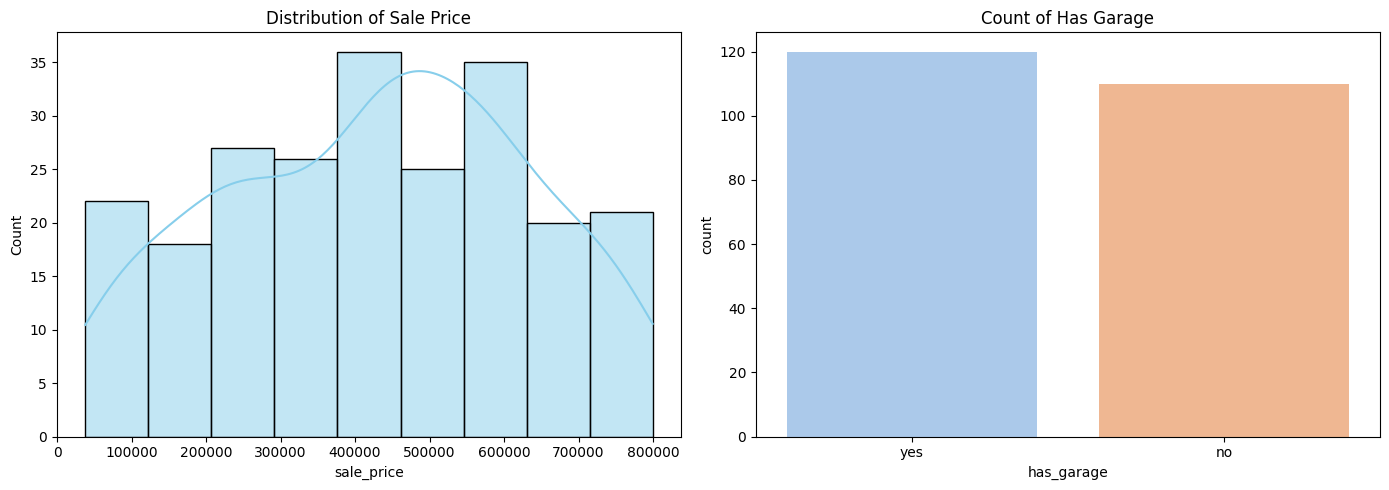

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['sale_price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Sale Price')
sns.countplot(data=df, x='has_garage', hue='has_garage', ax=axes[1], palette='pastel', legend=False)
axes[1].set_title('Count of Has Garage')
plt.tight_layout()
plt.show()

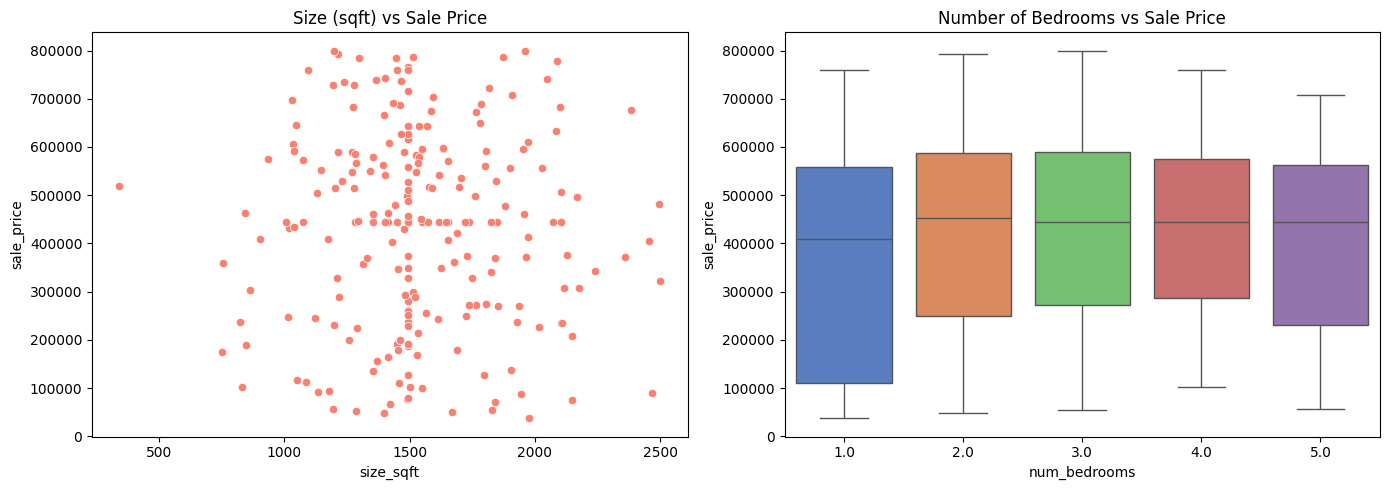

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df[df['size_sqft'] < 10000], x='size_sqft', y='sale_price', ax=axes[0], color='salmon')
axes[0].set_title('Size (sqft) vs Sale Price')
sns.boxplot(data=df, x='num_bedrooms', y='sale_price', hue='num_bedrooms', ax=axes[1], palette='muted', legend=False)
axes[1].set_title('Number of Bedrooms vs Sale Price')
plt.tight_layout()
plt.show()

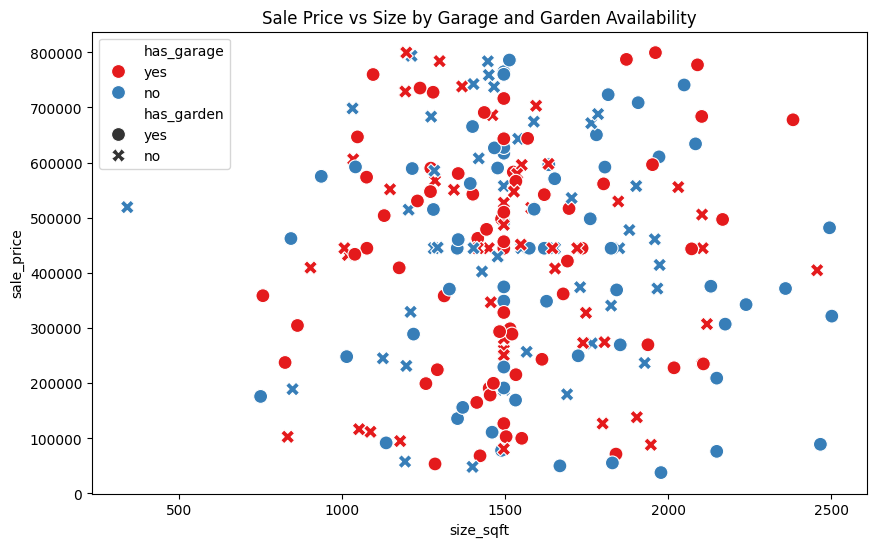

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[df['size_sqft'] < 10000], x='size_sqft', y='sale_price', hue='has_garage', style='has_garden', palette='Set1', s=100)
plt.title('Sale Price vs Size by Garage and Garden Availability')
plt.show()

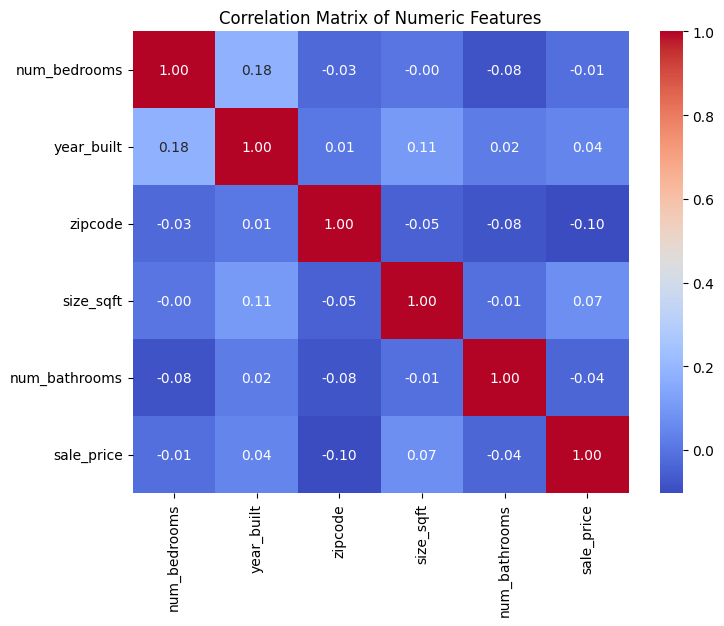

In [10]:
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()